# Chapter 4: Convolutional Networks in Medicine: CNN and FCN

This notebook collects the runnable examples of *Chapter 4: Convolutional Networks in Medicine: CNN and FCN* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- define the key terms of convolutional networks and their synonyms.
- compute the size of a feature map with the formula L′ = (L − K + 2P)/S + 1.
- implement and train a complete CNN from scratch.
- analyze examples of CNN applications in medical papers.
- explain the difference between a CNN and an FCN and the structure of U-Net.
- evaluate segmentation with the Dice and IoU metrics.
- build and train a CNN and a small U-Net with the PyTorch framework.


In [1]:
%matplotlib inline

## Example 4.1: Computing the size of the feature map

Script version: `example_4_1.py`

In [2]:
# Example 4.1: Computing the feature map size with the formula L' = (L - K + 2P) / S + 1
def feature_map_size(L, K, P=0, S=1):
    return (L - K + 2 * P) // S + 1
 
# three examples from the slides: smaller, same and larger output
for L, K, P, S in [(5, 3, 1, 2), (5, 3, 1, 1), (5, 3, 2, 1)]:
    print(f"L={L}, K={K}, P={P}, S={S}  ->  L' = {feature_map_size(L, K, P, S)}")
 
# "same" padding for an odd kernel: P = (K - 1) / 2 with S = 1
for K in (3, 5, 7):
    print(f"K={K}: same padding P={(K - 1) // 2} keeps 224 -> {feature_map_size(224, K, (K - 1) // 2)}")

L=5, K=3, P=1, S=2  ->  L' = 3
L=5, K=3, P=1, S=1  ->  L' = 5
L=5, K=3, P=2, S=1  ->  L' = 7
K=3: same padding P=1 keeps 224 -> 224
K=5: same padding P=2 keeps 224 -> 224
K=7: same padding P=3 keeps 224 -> 224


## Example 4.2: A complete CNN from scratch with NumPy, including backpropagation

Script version: `example_4_2.py`

epoch 10: train acc = 0.759 | test acc = 0.749


epoch 20: train acc = 0.894 | test acc = 0.871


epoch 30: train acc = 0.986 | test acc = 0.978


epoch 40: train acc = 0.993 | test acc = 0.980
Trainable parameters: 1370
Confusion matrix (rows = true digit):
 [[45  0  0  0  0  0  0  0  0  0]
 [ 0 46  0  0  0  0  0  0  0  0]
 [ 0  1 43  0  0  0  0  0  0  0]
 [ 0  0  0 45  0  0  0  1  0  0]
 [ 0  0  0  0 43  0  0  0  0  2]
 [ 0  0  0  1  0 45  0  0  0  0]
 [ 0  1  0  0  0  0 44  0  0  0]
 [ 0  0  0  0  0  0  0 45  0  0]
 [ 0  2  0  0  0  0  0  1 40  0]
 [ 0  0  0  0  0  0  0  0  0 45]]


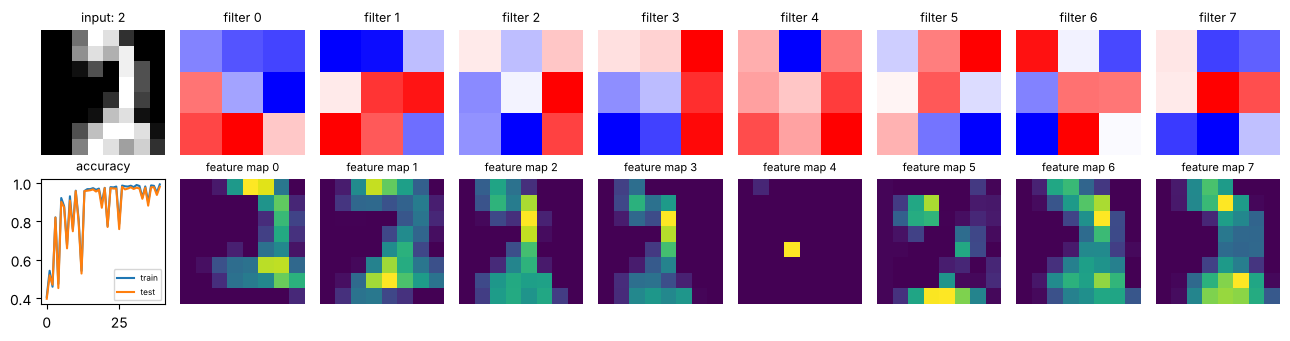

In [3]:
# Example 4.2: A complete convolutional network from scratch with NumPy
# Input 8x8 -> Conv(3x3, 8 filters, same) -> ReLU -> MaxPool(2x2) -> Flatten -> Dense(10) -> Softmax
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
 
rng = np.random.default_rng(0)
digits = load_digits()                                # 1797 handwritten digits, 8x8 pixels
X = digits.images / 16.0
X_tr, X_te, y_tr, y_te = train_test_split(X, digits.target, test_size=0.25,
                                          stratify=digits.target, random_state=0)
 
def im2col(x, k=3, p=1):
    """(N, H, W) -> (N, H*W, k*k): every k x k patch becomes one row."""
    N, H, W = x.shape
    xp = np.pad(x, ((0, 0), (p, p), (p, p)))
    cols = np.empty((N, H * W, k * k))
    for i in range(H):
        for j in range(W):
            cols[:, i * W + j, :] = xp[:, i:i + k, j:j + k].reshape(N, -1)
    return cols
 
F = 8                                                 # number of filters
Wc = rng.normal(0, 0.3, (9, F)); bc = np.zeros(F)     # conv filters (3x3 = 9 weights each)
Wd = rng.normal(0, 0.1, (4 * 4 * F, 10)); bd = np.zeros(10)
 
def forward(x):
    cols = im2col(x)                                  # (N, 64, 9)
    z = cols @ Wc + bc                                # convolution  (N, 64, F)
    a = np.maximum(z, 0).reshape(-1, 8, 8, F)         # ReLU
    blocks = a.reshape(-1, 4, 2, 4, 2, F).transpose(0, 1, 3, 5, 2, 4).reshape(-1, 4, 4, F, 4)
    pooled = blocks.max(-1)                           # max pooling 2x2 -> (N, 4, 4, F)
    flat = pooled.reshape(len(x), -1)
    logits = flat @ Wd + bd
    e = np.exp(logits - logits.max(1, keepdims=True))
    return cols, z, blocks, flat, e / e.sum(1, keepdims=True)
 
lr, history = 0.1, []
for epoch in range(40):
    order = rng.permutation(len(X_tr))
    for start in range(0, len(order), 32):            # mini-batches of 32
        idx = order[start:start + 32]
        x, t = X_tr[idx], y_tr[idx]
        cols, z, blocks, flat, prob = forward(x)
        n = len(x)
        d_logits = prob.copy(); d_logits[np.arange(n), t] -= 1; d_logits /= n
        dWd = flat.T @ d_logits; dbd = d_logits.sum(0)
        d_pooled = (d_logits @ Wd.T).reshape(n, 4, 4, F)
        mask = blocks == blocks.max(-1, keepdims=True)            # where the max came from
        d_blocks = mask * d_pooled[..., None]
        d_a = d_blocks.reshape(n, 4, 4, F, 2, 2).transpose(0, 1, 4, 2, 5, 3).reshape(n, 64, F)
        d_z = d_a * (z > 0)                                       # back through ReLU
        dWc = np.einsum("npk,npf->kf", cols, d_z); dbc = d_z.sum((0, 1))
        Wd -= lr * dWd; bd -= lr * dbd; Wc -= lr * dWc; bc -= lr * dbc
    acc_tr = np.mean(forward(X_tr)[-1].argmax(1) == y_tr)
    acc_te = np.mean(forward(X_te)[-1].argmax(1) == y_te)
    history.append((acc_tr, acc_te))
    if epoch % 10 == 9:
        print(f"epoch {epoch + 1:>2}: train acc = {acc_tr:.3f} | test acc = {acc_te:.3f}")
 
pred = forward(X_te)[-1].argmax(1)
print("Trainable parameters:", Wc.size + bc.size + Wd.size + bd.size)
print("Confusion matrix (rows = true digit):\n", confusion_matrix(y_te, pred))
 
fig, ax = plt.subplots(2, 9, figsize=(13, 3.4))
ax[0, 0].imshow(X_te[0], cmap="gray"); ax[0, 0].set_title(f"input: {y_te[0]}", fontsize=9)
fmaps = np.maximum(im2col(X_te[:1]) @ Wc + bc, 0).reshape(8, 8, F)
for f in range(F):
    ax[0, f + 1].imshow(Wc[:, f].reshape(3, 3), cmap="bwr"); ax[0, f + 1].set_title(f"filter {f}", fontsize=9)
    ax[1, f + 1].imshow(fmaps[:, :, f], cmap="viridis"); ax[1, f + 1].set_title(f"feature map {f}", fontsize=8)
ax[1, 0].plot([h[0] for h in history], label="train"); ax[1, 0].plot([h[1] for h in history], label="test")
ax[1, 0].set_title("accuracy", fontsize=9); ax[1, 0].legend(fontsize=6)
for a in ax.ravel()[1:]:
    if a is not ax[1, 0]: a.axis("off")
ax[0, 0].axis("off")
plt.tight_layout(); plt.savefig("fig4_1.png", dpi=300)

## Example 4.3: Reconstructing the dimensions and number of parameters of the paper's network

Script version: `example_4_3.py`

In [4]:
# Example 4.3: Reconstructing the CNN architecture table of the glioblastoma classification paper and computing dimensions and parameters
def out_size(L, K, P, S): return (L - K + 2 * P) // S + 1
 
layers = [("Conv1+ReLU", "conv", 5, 32), ("Pool1", "pool", 2, None),
          ("Conv2+ReLU", "conv", 5, 32), ("Pool2", "pool", 2, None),
          ("Conv3+ReLU", "conv", 5, 48), ("Pool3", "pool", 2, None),
          ("Conv4+ReLU", "conv", 5, 48), ("Pool4", "pool", 2, None),
          ("Conv5+ReLU", "conv", 5, 64), ("Conv6+ReLU", "conv", 5, 64),
          ("Pool6", "pool", 2, None), ("Conv7+ReLU", "conv", 5, 128)]
 
size, ch, total = 224, 3, 0          # input image resized from 1000x1000 to 224x224 (RGB)
print(f"{'layer':<12}{'filter':<8}{'maps':>6}{'spatial':>12}{'params':>12}")
for name, kind, k, n in layers:
    if kind == "conv":
        size = out_size(size, k, (k - 1) // 2, 1)          # 'same' padding, stride 1
        params = k * k * ch * n + n; ch = n
    else:
        size = out_size(size, k, 0, 2); params = 0
    total += params
    print(f"{name:<12}{f'{k}x{k}':<8}{ch:>6}{f'{size}x{size}':>12}{params:>12,}")
flat = size * size * ch
for name, units in [("FC1+ReLU", 1024), ("FC2+Softmax", 2)]:
    params = flat * units + units; total += params; flat = units
    print(f"{name:<12}{'':<8}{units:>6}{'1x1':>12}{params:>12,}")
print(f"Total trainable parameters: {total:,}")

layer       filter    maps     spatial      params
Conv1+ReLU  5x5         32     224x224       2,432
Pool1       2x2         32     112x112           0
Conv2+ReLU  5x5         32     112x112      25,632
Pool2       2x2         32       56x56           0
Conv3+ReLU  5x5         48       56x56      38,448
Pool3       2x2         48       28x28           0
Conv4+ReLU  5x5         48       28x28      57,648
Pool4       2x2         48       14x14           0
Conv5+ReLU  5x5         64       14x14      76,864
Conv6+ReLU  5x5         64       14x14     102,464
Pool6       2x2         64         7x7           0
Conv7+ReLU  5x5        128         7x7     204,928
FC1+ReLU              1024         1x1   6,423,552
FC2+Softmax              2         1x1       2,050
Total trainable parameters: 6,934,018


## Example 4.4: Four-fold cross-validation in the style of medical papers

Script version: `example_4_4.py`

In [5]:
# Example 4.4: K-fold cross-validation — reporting accuracy in the style of medical papers
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
 
X, y = load_digits(return_X_y=True)
model = MLPClassifier(hidden_layer_sizes=(64,), max_iter=400, random_state=0)
cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=0)
scores = cross_val_score(model, X / 16, y, cv=cv)
for i, s in enumerate(scores, 1):
    print(f"Fold {i}: accuracy = {100 * s:.1f}%")
print(f"Average: {100 * scores.mean():.1f}%  (± {100 * scores.std():.1f})")

Fold 1: accuracy = 98.2%
Fold 2: accuracy = 97.3%
Fold 3: accuracy = 98.0%
Fold 4: accuracy = 97.8%
Average: 97.8%  (± 0.3)


## Example 4.5: Common data augmentation methods on a retinal image

Script version: `example_4_5.py`

Original         shape=(256, 256) mean intensity=0.324
Horizontal flip  shape=(256, 256) mean intensity=0.324
Rotation 15°     shape=(256, 256) mean intensity=0.333
Zoom 1.2x        shape=(256, 256) mean intensity=0.407
Brightness +20%  shape=(256, 256) mean intensity=0.389
Gaussian noise   shape=(256, 256) mean intensity=0.328


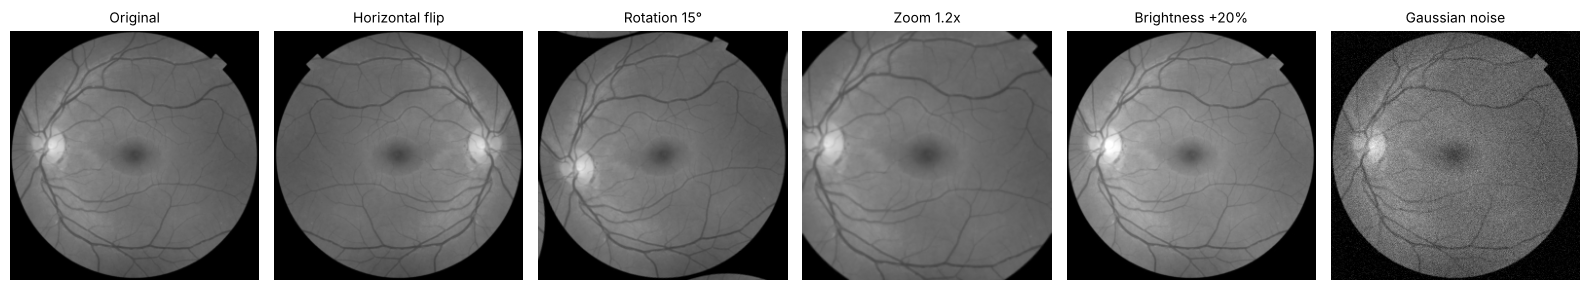

In [6]:
# Example 4.5: Data augmentation for medical images
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import data, color, transform
 
rng = np.random.default_rng(0)
img = transform.resize(color.rgb2gray(data.retina()), (256, 256))
 
aug = {
    "Original": img,
    "Horizontal flip": img[:, ::-1],
    "Rotation 15°": ndi.rotate(img, 15, reshape=False, mode="reflect"),
    "Zoom 1.2x": transform.resize(img[21:235, 21:235], (256, 256)),
    "Brightness +20%": np.clip(img * 1.2, 0, 1),
    "Gaussian noise": np.clip(img + rng.normal(0, 0.04, img.shape), 0, 1),
}
for name, a in aug.items():
    print(f"{name:<16} shape={a.shape} mean intensity={a.mean():.3f}")
 
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
for a, (name, im) in zip(ax, aug.items()):
    a.imshow(im, cmap="gray", vmin=0, vmax=1); a.set_title(name, fontsize=10); a.axis("off")
plt.tight_layout(); plt.savefig("fig4_3.png", dpi=300)

## Example 4.6: Upsampling with nearest neighbor, bed of nails, and transposed convolution

Script version: `example_4_6.py`

In [7]:
# Example 4.6: Upsampling — unpooling and transposed convolution
import numpy as np
 
x = np.array([[1, 2],
              [3, 4]])
 
nearest = x.repeat(2, axis=0).repeat(2, axis=1)              # nearest-neighbor upsampling
bed_of_nails = np.zeros((4, 4), int); bed_of_nails[::2, ::2] = x
 
def transpose_conv(x, k, stride=2):
    n, kk = x.shape[0], k.shape[0]
    out = np.zeros(((n - 1) * stride + kk,) * 2)
    for i in range(n):
        for j in range(n):          # every input pixel "stamps" a scaled copy of the kernel
            out[i*stride:i*stride+kk, j*stride:j*stride+kk] += x[i, j] * k
    return out
 
k = np.array([[1, 1, 0],
              [1, 1, 0],
              [0, 0, 0]])
print("Nearest-neighbor upsampling:\n", nearest)
print("Bed-of-nails unpooling:\n", bed_of_nails)
print("Transpose convolution (stride 2, 3x3 kernel):\n", transpose_conv(x, k).astype(int))

Nearest-neighbor upsampling:
 [[1 1 2 2]
 [1 1 2 2]
 [3 3 4 4]
 [3 3 4 4]]
Bed-of-nails unpooling:
 [[1 0 2 0]
 [0 0 0 0]
 [3 0 4 0]
 [0 0 0 0]]
Transpose convolution (stride 2, 3x3 kernel):
 [[1 1 2 2 0]
 [1 1 2 2 0]
 [3 3 4 4 0]
 [3 3 4 4 0]
 [0 0 0 0 0]]


## Example 4.7: Pixel-by-pixel segmentation and computing Dice and IoU

Script version: `example_4_7.py`

Training pixels: 55296 | features per pixel: 10
Global threshold -> Dice = 0.524, IoU = 0.355
Pixel classifier -> Dice = 0.985, IoU = 0.970


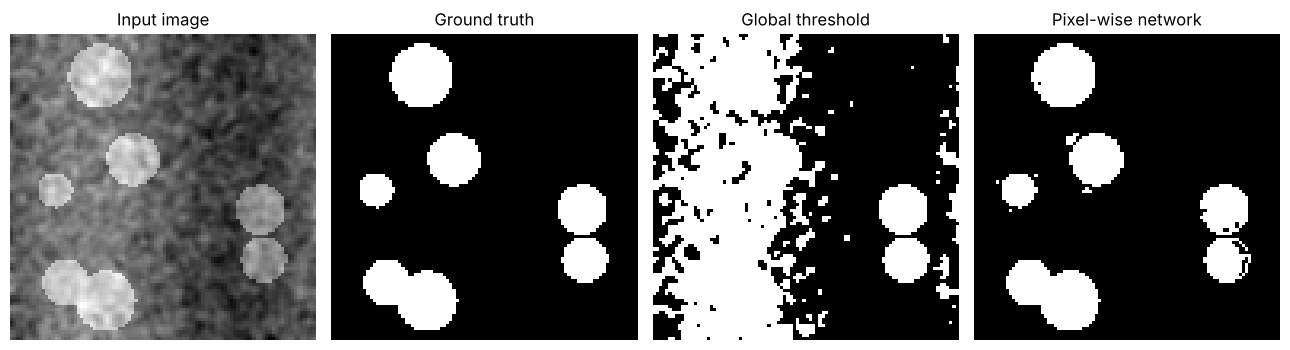

In [8]:
# Example 4.7: Pixel-by-pixel segmentation (the FCN idea) and the Dice and IoU metrics
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from sklearn.neural_network import MLPClassifier
 
rng = np.random.default_rng(1)
 
def make_image(n=96, n_cells=7):
    """Synthetic microscopy image with round 'cells' and its ground-truth mask."""
    yy, xx = np.mgrid[:n, :n]
    mask = np.zeros((n, n), bool)
    for _ in range(n_cells):
        cy, cx, r = rng.uniform(10, n - 10, 2).tolist() + [rng.uniform(5, 11)]
        mask |= (yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2
    img = 0.35 + 0.35 * mask + ndi.gaussian_filter(rng.normal(0, 0.25, (n, n)), 1)
    img += 0.15 * np.sin(xx / 15)                  # uneven illumination
    return img, mask
 
def pixel_features(img):
    """A small filter bank = what the conv layers of an FCN learn automatically."""
    feats = [img]
    for s in (1, 2, 4):
        feats += [ndi.gaussian_filter(img, s),
                  ndi.gaussian_laplace(img, s),
                  ndi.gaussian_gradient_magnitude(img, s)]
    return np.stack(feats, -1).reshape(-1, len(feats))
 
def dice(a, b):  return 2 * (a & b).sum() / (a.sum() + b.sum())
def iou(a, b):   return (a & b).sum() / (a | b).sum()
 
train = [make_image() for _ in range(6)]
Xtr = np.vstack([pixel_features(i) for i, _ in train])
ytr = np.concatenate([m.ravel() for _, m in train])
clf = MLPClassifier(hidden_layer_sizes=(16,), max_iter=300, random_state=0).fit(Xtr, ytr)
 
test_img, test_mask = make_image()
pred = clf.predict(pixel_features(test_img)).reshape(test_mask.shape).astype(bool)
thresh = test_img > test_img.mean()                # naive baseline: global threshold
 
print("Training pixels:", len(ytr), "| features per pixel:", Xtr.shape[1])
print(f"Global threshold -> Dice = {dice(thresh, test_mask):.3f}, IoU = {iou(thresh, test_mask):.3f}")
print(f"Pixel classifier -> Dice = {dice(pred, test_mask):.3f}, IoU = {iou(pred, test_mask):.3f}")
 
fig, ax = plt.subplots(1, 4, figsize=(13, 3.5))
for a, (im, t) in zip(ax, [(test_img, "Input image"), (test_mask, "Ground truth"),
                           (thresh, "Global threshold"), (pred, "Pixel-wise network")]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig("fig4_2.png", dpi=300)

## Example 4.8: An occlusion sensitivity map for a CNN

Script version: `example_4_8.py`

test image 0: digit 2, P(correct class) = 0.990, most important region (row, col) = (5, 4)
test image 3: digit 9, P(correct class) = 0.999, most important region (row, col) = (3, 5)
test image 7: digit 4, P(correct class) = 0.993, most important region (row, col) = (5, 4)
test image 11: digit 1, P(correct class) = 0.999, most important region (row, col) = (2, 4)


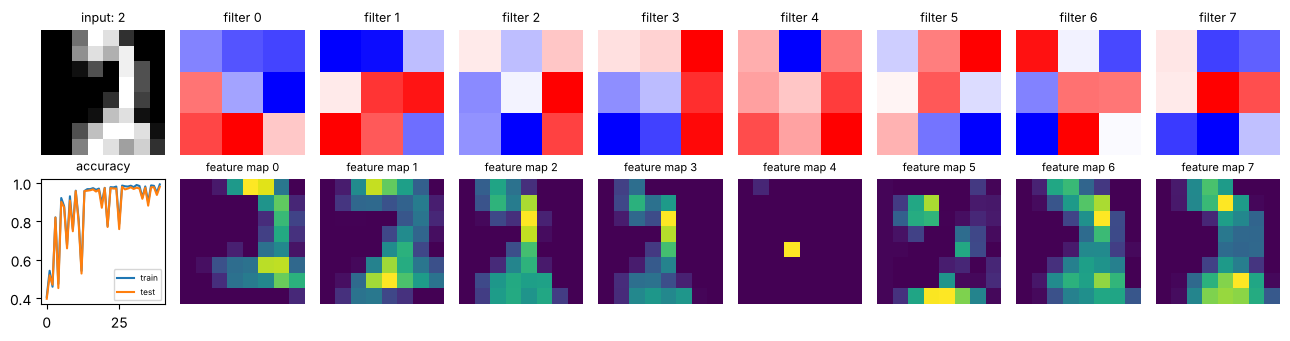

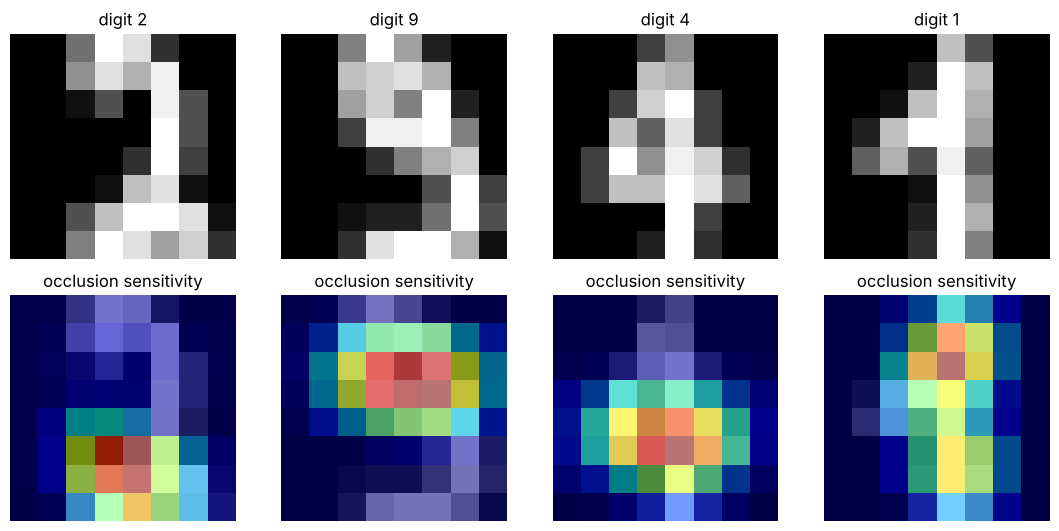

In [9]:
# Example 4.8: Interpretability with an occlusion sensitivity map
import numpy as np
import matplotlib.pyplot as plt
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):
    import example_4_2 as cnn        # re-uses (and re-trains) the CNN of Example 4.2 (saved as example_4_2.py)
 
def occlusion_map(img, label, size=3):
    base = cnn.forward(img[None])[-1][0, label]
    heat = np.zeros_like(img)
    for i in range(8 - size + 1):
        for j in range(8 - size + 1):
            x = img.copy(); x[i:i + size, j:j + size] = 0          # hide a 3x3 patch
            drop = base - cnn.forward(x[None])[-1][0, label]
            heat[i:i + size, j:j + size] += drop
    return base, heat
 
fig, ax = plt.subplots(2, 4, figsize=(11, 5.4))
for k, idx in enumerate([0, 3, 7, 11]):
    img, label = cnn.X_te[idx], cnn.y_te[idx]
    base, heat = occlusion_map(img, label)
    print(f"test image {idx}: digit {label}, P(correct class) = {base:.3f}, "
          f"most important region (row, col) = {tuple(int(v) for v in np.unravel_index(heat.argmax(), heat.shape))}")
    ax[0, k].imshow(img, cmap="gray"); ax[0, k].set_title(f"digit {label}")
    ax[1, k].imshow(img, cmap="gray"); ax[1, k].imshow(heat, cmap="jet", alpha=0.55)
    ax[1, k].set_title("occlusion sensitivity")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.savefig("fig4_4.png", dpi=300)

## Example 4.9: The CNN of Example 4.2, rebuilt in PyTorch

Script version: `example_4_9.py`

In [10]:
# Example 4.9: The CNN of Example 4.2, rebuilt in PyTorch
import numpy as np
import torch
from torch import nn
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

torch.manual_seed(0); torch.set_num_threads(1)
digits = load_digits()
X = torch.tensor(digits.images / 16.0, dtype=torch.float32).unsqueeze(1)   # (N, 1, 8, 8): one channel
y = torch.tensor(digits.target)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),   # 8 filters of 3x3, "same" padding
            nn.ReLU(),
            nn.MaxPool2d(2))                             # 8x8 -> 4x4
        self.classifier = nn.Linear(8 * 4 * 4, 10)      # softmax is inside the loss function
    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))

model = SmallCNN()
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
loss_fn = nn.CrossEntropyLoss()
opt = torch.optim.Adam(model.parameters(), lr=0.01)
loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)

for epoch in range(1, 41):
    model.train()
    for xb, yb in loader:
        opt.zero_grad()                     # 1) clear the old gradients
        loss = loss_fn(model(xb), yb)       # 2) forward pass and loss
        loss.backward()                     # 3) backpropagation: autograd computes every gradient
        opt.step()                          # 4) update the weights
    if epoch % 10 == 0:
        model.eval()
        with torch.no_grad():
            acc_tr = (model(X_tr).argmax(1) == y_tr).float().mean().item()
            acc_te = (model(X_te).argmax(1) == y_te).float().mean().item()
        print(f"epoch {epoch}: train acc = {acc_tr:.3f} | test acc = {acc_te:.3f}")

Trainable parameters: 1370


epoch 10: train acc = 0.979 | test acc = 0.973


epoch 20: train acc = 0.996 | test acc = 0.978


epoch 30: train acc = 0.999 | test acc = 0.980


epoch 40: train acc = 0.990 | test acc = 0.973


## Example 4.10: A small U-Net in PyTorch for segmenting the synthetic cells of Example 4.7

Script version: `example_4_10.py`

Trainable parameters: 29321


epoch 20: loss = 0.2125 | test Dice = 0.000


epoch 40: loss = 0.1102 | test Dice = 0.944


epoch 60: loss = 0.0259 | test Dice = 0.964
global threshold: test Dice = 0.515


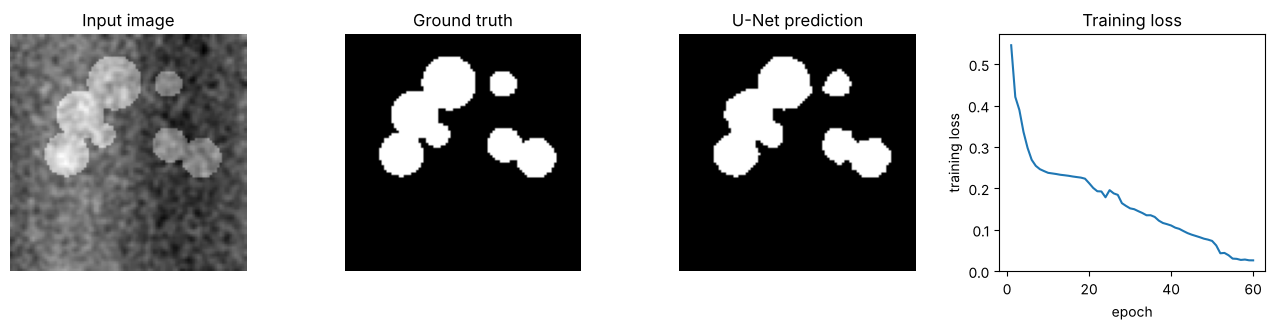

In [11]:
# Example 4.10: A small U-Net in PyTorch for segmenting the synthetic cells of Example 4.7
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

rng = np.random.default_rng(1); torch.manual_seed(0); torch.set_num_threads(1)

def make_image(n=96, n_cells=7):                 # the same generator as in Example 4.7
    yy, xx = np.mgrid[:n, :n]
    mask = np.zeros((n, n), bool)
    for _ in range(n_cells):
        cy, cx, r = rng.uniform(10, n - 10, 2).tolist() + [rng.uniform(5, 11)]
        mask |= (yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2
    img = 0.35 + 0.35 * mask + ndi.gaussian_filter(rng.normal(0, 0.25, (n, n)), 1)
    img += 0.15 * np.sin(xx / 15)
    return img, mask

def to_tensor(pairs):
    imgs, masks = zip(*pairs)
    return (torch.tensor(np.array(imgs), dtype=torch.float32).unsqueeze(1),
            torch.tensor(np.array(masks), dtype=torch.float32).unsqueeze(1))

X_tr, Y_tr = to_tensor([make_image() for _ in range(40)])
X_te, Y_te = to_tensor([make_image() for _ in range(10)])

def block(c_in, c_out):                           # two 3x3 convolutions with ReLU
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(),
                         nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU())

class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1, self.enc2 = block(1, 8), block(8, 16)      # encoder (contracting path)
        self.pool = nn.MaxPool2d(2)
        self.bottom = block(16, 32)
        self.up2, self.dec2 = nn.ConvTranspose2d(32, 16, 2, stride=2), block(32, 16)   # decoder
        self.up1, self.dec1 = nn.ConvTranspose2d(16, 8, 2, stride=2), block(16, 8)
        self.out = nn.Conv2d(8, 1, 1)                          # one logit per pixel
    def forward(self, x):
        e1 = self.enc1(x); e2 = self.enc2(self.pool(e1)); b = self.bottom(self.pool(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], 1))       # skip connection
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))      # skip connection
        return self.out(d1)

def dice(pred, true):
    return (2 * (pred * true).sum() / (pred.sum() + true.sum())).item()

model = TinyUNet()
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))
opt = torch.optim.Adam(model.parameters(), lr=0.003)
loss_fn = nn.BCEWithLogitsLoss()
losses = []
for epoch in range(1, 61):
    model.train()
    for k in range(0, 40, 8):                                  # mini-batches of 8 images
        opt.zero_grad()
        loss = loss_fn(model(X_tr[k:k + 8]), Y_tr[k:k + 8]); loss.backward(); opt.step()
    losses.append(loss.item())
    if epoch % 20 == 0:
        model.eval()
        with torch.no_grad():
            pred = (model(X_te) > 0).float()
        print(f"epoch {epoch}: loss = {loss.item():.4f} | test Dice = {dice(pred, Y_te):.3f}")

thresh = (X_te > X_te.mean(dim=(2, 3), keepdim=True)).float()  # baseline of Example 4.7
print(f"global threshold: test Dice = {dice(thresh, Y_te):.3f}")

fig, ax = plt.subplots(1, 4, figsize=(13, 3.4))
for a, (im, t) in zip(ax[:3], [(X_te[0, 0], "Input image"), (Y_te[0, 0], "Ground truth"), (pred[0, 0], "U-Net prediction")]):
    a.imshow(im, cmap="gray"); a.set_title(t); a.axis("off")
ax[3].plot(range(1, 61), losses); ax[3].set_xlabel("epoch"); ax[3].set_ylabel("training loss"); ax[3].set_title("Training loss")
plt.tight_layout(); plt.savefig("fig4_17.png", dpi=300)